# **Import and Load**

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [3]:
customer_service_tickets = pd.read_csv("../raw/customer_service_tickets.csv")
users = pd.read_csv("../raw/users.csv")
sellers = pd.read_csv("../raw/sellers.csv")
transactions = pd.read_csv("../raw/transactions.csv")
deliveries = pd.read_csv("../raw/deliveries.csv")

In [4]:
clean_customer_service_tickets = customer_service_tickets.copy()
clean_users = users.copy()
clean_sellers = sellers.copy()
clean_transactions = transactions.copy()
clean_deliveries = deliveries.copy()

# **Data Cleaning**
*Tiap nomor mengikuti tiap poin di bagian Catatan Kualitas Data di Brief Peserta*

## **1. Standardization of Values**
Sejumlah kolom kategorikal (mis. lokasi, metode pembayaran) memiliki variasi penulisan yang belum
distandardisasi — perlu dibersihkan sebelum dikelompokkan atau dibandingkan.

### 1.1 Cek Kolom Metode Pembayaran di transactions.csv

In [5]:
clean_transactions["payment_method"].unique()

<ArrowStringArray>
[   'Bank Transfer',              'cod',        'ShopeePay',
              'COD',            'GoPay',              'OVO',
             'DANA',             'QRIS',           'GO-PAY',
      'Credit Card',             'dana',            'Gopay',
    'Transfer Bank',              'ovo',       'Shopee Pay',
       'Mandiri VA', 'Cash on Delivery',           'BNI VA',
    'bank transfer',             'qris',            'gopay',
           'BCA VA',     'Kartu Kredit',        'shopeepay',
      'credit card',             'Dana',              'Ovo']
Length: 27, dtype: str

Terlihat bahwa belum dilakukan standarisasi penamaaan metode pembayaran, sehingga metode-metode yang seharusnya sama dianggap berbeda (contoh: 'cod' dan 'COD').

In [6]:
payment_mapping = {
    # Cash on Delivery
    'cod': 'Cash on Delivery',
    'COD': 'Cash on Delivery',

    # GoPay
    'GO-PAY': 'GoPay',
    'Gopay': 'GoPay',
    'gopay': 'GoPay',

    # DANA
    'dana': 'DANA',
    'Dana': 'DANA',

    # ShopeePay
    'Shopee Pay': 'ShopeePay',
    'shopeepay': 'ShopeePay',

    # QRIS
    'qris': 'QRIS',

    # OVO
    'ovo': 'OVO',
    'Ovo': 'OVO',

    # Bank Transfer (including Indonesian translation and Virtual Accounts)
    'Transfer Bank': 'Bank Transfer',
    'bank transfer': 'Bank Transfer',
    'Mandiri VA': 'Bank Transfer',
    'BNI VA': 'Bank Transfer',
    'BCA VA': 'Bank Transfer',

    # Credit Card (including Indonesian translation)
    'credit card': 'Credit Card',
    'Kartu Kredit': 'Credit Card'
}

clean_transactions["payment_method"] = clean_transactions["payment_method"].replace(payment_mapping)

In [7]:
clean_transactions["payment_method"].unique()

<ArrowStringArray>
[   'Bank Transfer', 'Cash on Delivery',        'ShopeePay',
            'GoPay',              'OVO',             'DANA',
             'QRIS',      'Credit Card']
Length: 8, dtype: str

### 1.2 Cek kolom lokasi (kota, domisili, provinsi) di berbagai dataset

In [8]:
# Cek di users.csv
clean_users["location"].unique()

<ArrowStringArray>
[   'Surabaya',      'Manado',       'Medan', 'DKI Jakarta',    'Semarang',
     'Jakarta',       'Batam',      'Malang',   'Pontianak',  'Balikpapan',
     'Bandung',   'Palembang',    'Denpasar',  'Yogyakarta',    'Makassar',
      'Padang',     'jakarta',     'JAKARTA']
Length: 18, dtype: str

In [9]:
# Standarisasi Nama Kota
location_mapping = {
    'DKI Jakarta': 'Jakarta',
    'jakarta': 'Jakarta',
    'JAKARTA': 'Jakarta'
}

clean_users["location"] = clean_users["location"].replace(location_mapping)
clean_users["location"].unique()

<ArrowStringArray>
[  'Surabaya',     'Manado',      'Medan',    'Jakarta',   'Semarang',
      'Batam',     'Malang',  'Pontianak', 'Balikpapan',    'Bandung',
  'Palembang',   'Denpasar', 'Yogyakarta',   'Makassar',     'Padang']
Length: 15, dtype: str

In [10]:
# Cek di deliveries.csv
clean_deliveries["destination_city"].unique()

<ArrowStringArray>
[     'Malang',      'Padang',    'Surabaya',     'JAKARTA',    'Makassar',
     'Jakarta',     'Bandung',    'Semarang',  'Yogyakarta',     'jakarta',
       'Medan',   'Palembang',    'Denpasar',      'Manado',   'Pontianak',
 'DKI Jakarta',       'Batam',  'Balikpapan']
Length: 18, dtype: str

In [11]:
clean_deliveries["destination_city"] = clean_deliveries["destination_city"].replace(location_mapping)
clean_deliveries["destination_city"].unique()

<ArrowStringArray>
[    'Malang',     'Padang',   'Surabaya',    'Jakarta',   'Makassar',
    'Bandung',   'Semarang', 'Yogyakarta',      'Medan',  'Palembang',
   'Denpasar',     'Manado',  'Pontianak',      'Batam', 'Balikpapan']
Length: 15, dtype: str

## **2. Missing Values**
Tidak semua kolom kosong berarti error — sebagian mengikuti alur bisnis (mis. pesanan tanpa voucher,
pengguna tanpa kode referral), sebagian lain perlu ditelusuri polanya sebelum diisi atau dibuang.

### 2.1 Identifikasi Missing Values


In [12]:
total_mv_customer_service_tickets = clean_customer_service_tickets.isnull().sum().sum()
total_mv_users = clean_users.isnull().sum().sum()
total_mv_sellers = clean_sellers.isnull().sum().sum()
total_mv_transactions = clean_transactions.isnull().sum().sum()
total_mv_deliveries = clean_deliveries.isnull().sum().sum()

total_mv_customer_service_tickets_pct = total_mv_customer_service_tickets / clean_customer_service_tickets.size
total_mv_users_pct = total_mv_users / clean_users.size
total_mv_sellers_pct = total_mv_sellers / clean_sellers.size
total_mv_transactions_pct = total_mv_transactions / clean_transactions.size
total_mv_deliveries_pct = total_mv_deliveries / clean_deliveries.size

print("Total values customer service tickets :", clean_customer_service_tickets.size)
print(f"Total Missing Values customer service tickets: {total_mv_customer_service_tickets} ({total_mv_customer_service_tickets_pct:.2%})\n")

print("Total values users :", clean_users.size)
print(f"Total Missing Values: {total_mv_users} ({total_mv_users_pct:.2%})\n")

print("Total values sellers :", clean_sellers.size)
print(f"Total Missing Values: {total_mv_sellers} ({total_mv_sellers_pct:.2%})\n")

print("Total values transactions :", clean_transactions.size)
print(f"Total Missing Values: {total_mv_transactions} ({total_mv_transactions_pct:.2%})\n")

print("Total values deliveries :", clean_deliveries.size)
print(f"Total Missing Values: {total_mv_deliveries} ({total_mv_deliveries_pct:.2%})\n")


Total values customer service tickets : 315530
Total Missing Values customer service tickets: 9969 (3.16%)

Total values users : 687011
Total Missing Values: 50014 (7.28%)

Total values sellers : 11142
Total Missing Values: 0 (0.00%)

Total values transactions : 4589201
Total Missing Values: 113288 (2.47%)

Total values deliveries : 2876775
Total Missing Values: 87821 (3.05%)



#### 2.1.2 Menghitung jumlah baris yang memiliki nilai kosong

In [13]:
total_rows_mv_customer_service_tickets = clean_customer_service_tickets.isna().any(axis=1).sum()
total_rows_mv_users = clean_users.isnull().any(axis=1).sum()
total_rows_mv_sellers = clean_sellers.isnull().any(axis=1).sum()
total_rows_mv_transactions = clean_transactions.isnull().any(axis=1).sum()
total_rows_mv_deliveries = clean_deliveries.isnull().any(axis=1).sum()


total_rows_mv_customer_service_tickets_pct = total_rows_mv_customer_service_tickets / clean_customer_service_tickets.shape[0]
total_rows_mv_users_pct = total_rows_mv_users / clean_users.shape[0]
total_rows_mv_sellers_pct = total_rows_mv_sellers / clean_sellers.shape[0]
total_rows_mv_transactions_pct = total_rows_mv_transactions / clean_transactions.shape[0]
total_rows_mv_deliveries_pct = total_rows_mv_deliveries / clean_deliveries.shape[0]

print("Total rows customer service tickets :", clean_customer_service_tickets.shape[0])
print(f"Total Rows That Have Missing Values: {total_rows_mv_customer_service_tickets} ({total_rows_mv_customer_service_tickets_pct:.2%})\n")

print("Total rows users :", clean_users.shape[0])
print(f"Total Rows That Have Missing Values: {total_rows_mv_users} ({total_rows_mv_users_pct:.2%})\n")

print("Total rows sellers :", clean_sellers.shape[0])
print(f"Total Rows That Have Missing Values: {total_rows_mv_sellers} ({total_rows_mv_sellers_pct:.2%})\n")

print("Total rows transactions :", clean_transactions.shape[0])
print(f"Total Rows That Have Missing Values: {total_rows_mv_transactions} ({total_rows_mv_transactions_pct:.2%})\n")

print("Total rows deliveries :", clean_deliveries.shape[0])
print(f"Total Rows That Have Missing Values: {total_rows_mv_deliveries} ({total_rows_mv_deliveries_pct:.2%})\n")

Total rows customer service tickets : 31553
Total Rows That Have Missing Values: 9969 (31.59%)

Total rows users : 52847
Total Rows That Have Missing Values: 45646 (86.37%)

Total rows sellers : 1238
Total Rows That Have Missing Values: 0 (0.00%)

Total rows transactions : 269953
Total Rows That Have Missing Values: 113288 (41.97%)

Total rows deliveries : 261525
Total Rows That Have Missing Values: 84894 (32.46%)



In [14]:
clean_customer_service_tickets[clean_customer_service_tickets.isnull().any(axis=1)].sample(5, random_state=42)

,ticket_key,ticket_id,order_id,complaint_category,ticket_date,channel,resolution_status,resolution_time_hours,csat_score,agent_id
2193,2194,TKT-230124-6106,INV/230114/6715453,keterlambatan,2023-01-24,sosmed,resolved,18.7,NaN,AG-MDN-015
6070,6071,TKT-230417-4114,INV/230410/8921494,produk_rusak,2023-04-17,chat,escalated,0.5,NaN,AG-SBY-024
29314,29315,TKT-241102-3201,INV/241025/9350171,refund,2024-11-02,chat,pending,7.9,NaN,AG-MDN-015
344,345,TKT-241002-9320,INV/240928/4303493,keterlambatan,2024-10-02,telepon,escalated,9.5,NaN,AG-BDG-003
1393,1394,TKT-231225-3780,INV/231203/4266323,keterlambatan,2023-12-25,chat,resolved,40.6,NaN,AG-JKT-020


In [15]:
# Menampilkan sampel data yang memiliki nilai kosong
clean_users[clean_users.isnull().any(axis=1)].sample(5, random_state=42)

,user_id,join_date,gender,location,province,age,device_type,acquisition_channel,phone_verified,email_verified,referral_code_used,account_status,last_active_date
38028,R373C8P4KV,2021-08-24,Male,Surabaya,Jawa Timur,47,iOS,organic,0,1,NaN,active,2021-09-05
729,2G7S5D4PKP,2021-01-05,Male,Makassar,Sulawesi Selatan,46,Android,organic,1,0,NaN,active,2021-01-06
14418,AT8656RAPH,2024-08-23,NaN,Batam,Kepulauan Riau,58,Android,organic,1,1,NaN,active,2024-09-14
43808,UK6QJYGWXQ,2023-07-05,Female,Jakarta,DKI Jakarta,43,iOS,ads,1,1,NaN,active,2023-07-29
36592,Q734H6YBP4,2021-10-13,NaN,Bandung,Jawa Barat,26,iOS,organic,1,1,NaN,suspended,2023-08-02


#### 2.1.3 Menghitung jumlah nilai kosong tiap kolom

In [16]:
missing_summary_customer_service_tickets = pd.DataFrame({
    'Missing Count': clean_customer_service_tickets.isnull().sum(),
    'Missing (%)': (clean_customer_service_tickets.isnull().sum() / len(clean_customer_service_tickets) * 100).round(2)
})
missing_summary_users = pd.DataFrame({
    'Missing Count': clean_users.isnull().sum(),
    'Missing (%)': (clean_users.isnull().sum() / len(clean_users) * 100).round(2)
})

missing_summary_sellers = pd.DataFrame({
    'Missing Count': clean_sellers.isnull().sum(),
    'Missing (%)': (clean_sellers.isnull().sum() / len(clean_sellers) * 100).round(2)
})

missing_summary_transactions = pd.DataFrame({
    'Missing Count': clean_transactions.isnull().sum(),
    'Missing (%)': (clean_transactions.isnull().sum() / len(clean_transactions) * 100).round(2)
})

missing_summary_deliveries = pd.DataFrame({
    'Missing Count': clean_deliveries.isnull().sum(),
    'Missing (%)': (clean_deliveries.isnull().sum() / len(clean_deliveries) * 100).round(2)
})
print("Nilai kosong pada kolom Customer Service Tickets: ")
display(missing_summary_customer_service_tickets[missing_summary_customer_service_tickets['Missing Count'] > 0].sort_values('Missing (%)', ascending=False))

print("\nNilai Kosong pada kolom Users: ")
display(missing_summary_users[missing_summary_users['Missing Count'] > 0].sort_values('Missing (%)', ascending=False))

print("\nNilai Kosong pada kolom Sellers: ")
display(missing_summary_sellers[missing_summary_sellers['Missing Count'] > 0].sort_values('Missing (%)', ascending=False))

print("\nNilai Kosong pada kolom Transactions:")
display(missing_summary_transactions[missing_summary_transactions['Missing Count'] > 0].sort_values('Missing (%)', ascending=False))

print("\nNilai Kosong pada kolom Deliveries: ")
display(missing_summary_deliveries[missing_summary_deliveries['Missing Count'] > 0].sort_values('Missing (%)', ascending=False))

Nilai kosong pada kolom Customer Service Tickets: 


,Missing Count,Missing (%)
csat_score,9969,31.59



Nilai Kosong pada kolom Users: 


,Missing Count,Missing (%)
referral_code_used,44865,84.90
gender,5149,9.74



Nilai Kosong pada kolom Sellers: 


,Missing Count,Missing (%)



Nilai Kosong pada kolom Transactions:


,Missing Count,Missing (%)
voucher_type,113288,41.97



Nilai Kosong pada kolom Deliveries: 


,Missing Count,Missing (%)
courier_rating,77844,29.77
courier_name,9977,3.81


#### 2.1.4 Analisa Pola missing csat_score pada Tabel Customer Service Ticket





In [17]:
# Cek apakah proporsi missing merata disemua grup atau terkonsentrasi

print("=== Proporsi csat_score missing per resolution_status ===")
print(clean_customer_service_tickets.groupby('resolution_status')['csat_score'].apply(lambda x: x.isna().mean()).round(3))

print("\n=== Proporsi csat_score missing per channel ===")
print(clean_customer_service_tickets.groupby('channel')['csat_score'].apply(lambda x: x.isna().mean()).round(3))

print("\n=== Proporsi csat_score missing per complaint_category ===")
print(clean_customer_service_tickets.groupby('complaint_category')['csat_score'].apply(lambda x: x.isna().mean()).round(3))

print("\n=== Proporsi csat_score missing per agent_id ===")
print(clean_customer_service_tickets.groupby('agent_id')['csat_score'].apply(lambda x: x.isna().mean()).round(3))

print("\n=== Distribusi nilai csat_score yang ada (non-missing) ===")
print(clean_customer_service_tickets['csat_score'].value_counts(dropna=True, normalize=True).round(3))

=== Proporsi csat_score missing per resolution_status ===
resolution_status
escalated    1.000
pending      1.000
resolved     0.147
Name: csat_score, dtype: float64

=== Proporsi csat_score missing per channel ===
channel
chat       0.313
email      0.320
sosmed     0.316
telepon    0.318
Name: csat_score, dtype: float64

=== Proporsi csat_score missing per complaint_category ===
complaint_category
keterlambatan    0.320
kurir_kasar      0.308
lainnya          0.322
produk_rusak     0.315
refund           0.309
Name: csat_score, dtype: float64

=== Proporsi csat_score missing per agent_id ===
agent_id
AG-BDG-001    0.289
AG-BDG-002    0.339
AG-BDG-003    0.369
AG-BDG-004    0.320
AG-BDG-005    0.308
              ...  
AG-SBY-020    0.302
AG-SBY-021    0.315
AG-SBY-022    0.325
AG-SBY-023    0.305
AG-SBY-024    0.270
Name: csat_score, Length: 120, dtype: float64

=== Distribusi nilai csat_score yang ada (non-missing) ===
csat_score
3.0    0.314
4.0    0.255
2.0    0.214
5.0    0.114
1

In [18]:
clean_users

,user_id,join_date,gender,location,province,age,device_type,acquisition_channel,phone_verified,email_verified,referral_code_used,account_status,last_active_date
0,222FPT2RQE,2024-12-07,Female,Surabaya,Jawa Timur,35,Android,ads,1,1,NaN,active,2024-12-09
1,222TKKG47G,2023-11-10,Female,Surabaya,Jawa Timur,46,Android,organic,1,1,NaN,active,2023-12-02
2,2242MWUZJL,2023-10-14,Female,Manado,Sulawesi Utara,41,Android,affiliate,1,0,NaN,active,2023-10-27
3,224JW2JMEQ,2024-10-05,Male,Medan,Sumatera Utara,65,Android,referral,1,1,SVHZNJ,active,2024-10-13
4,224RUVDYHV,2020-12-19,Male,Jakarta,DKI Jakarta,51,Android,ads,1,1,NaN,active,2021-01-15
...,...,...,...,...,...,...,...,...,...,...,...,...,...
52842,ZZW4WE4TTL,2024-11-27,Female,Surabaya,Jawa Timur,33,Android,ads,1,1,NaN,active,2024-12-04
52843,ZZWLREUL3Q,2020-09-25,Male,Jakarta,DKI Jakarta,47,iOS,organic,1,1,NaN,active,2020-10-12
52844,ZZX6NDRML7,2024-10-21,Male,Jakarta,DKI Jakarta,56,Android,referral,1,1,7ZD7NH,active,2024-10-26
52845,ZZY9SUE2E2,2024-01-17,Female,Malang,Jawa Timur,42,iOS,organic,1,0,NaN,active,2024-02-07


#### 2.1.5 Analisa Pola missing referral_code_used pada Tabel users

In [19]:
print("=== Proporsi referral_code_used missing per acquisition_channel ===")
print(clean_users.groupby('acquisition_channel')['referral_code_used'].apply(lambda x: x.isna().mean()).round(3))

print("\n=== Proporsi referral_code_used missing per device_type ===")
print(clean_users.groupby('device_type')['referral_code_used'].apply(lambda x: x.isna().mean()).round(3))

print("\n=== Proporsi referral_code_used missing per account_status ===")
print(clean_users.groupby('account_status')['referral_code_used'].apply(lambda x: x.isna().mean()).round(3))

print("\n=== Proporsi referral_code_used missing per gender ===")
print(clean_users.groupby('gender')['referral_code_used'].apply(lambda x: x.isna().mean()).round(3))

print("\n=== Proporsi referral_code_used missing per province ===")
print(clean_users.groupby('province')['referral_code_used'].apply(lambda x: x.isna().mean()).round(3))

print("\n=== Proporsi referral_code_used missing per phone_verified ===")
print(clean_users.groupby('phone_verified')['referral_code_used'].apply(lambda x: x.isna().mean()).round(3))

print("\n=== Proporsi referral_code_used missing per email_verified ===")
print(clean_users.groupby('email_verified')['referral_code_used'].apply(lambda x: x.isna().mean()).round(3))

print("\n=== Distribusi nilai referral_code_used yang ada (non-missing) ===")
print(clean_users['referral_code_used'].value_counts(dropna=True, normalize=True).round(3))

=== Proporsi referral_code_used missing per acquisition_channel ===


acquisition_channel
ads          1.0
affiliate    1.0
organic      1.0
referral     0.0
Name: referral_code_used, dtype: float64

=== Proporsi referral_code_used missing per device_type ===
device_type
Android    0.848
Web        0.845
iOS        0.852
Name: referral_code_used, dtype: float64

=== Proporsi referral_code_used missing per account_status ===
account_status
active       0.849
inactive     0.852
suspended    0.834
Name: referral_code_used, dtype: float64

=== Proporsi referral_code_used missing per gender ===
gender
Female    0.851
Male      0.847
Name: referral_code_used, dtype: float64

=== Proporsi referral_code_used missing per province ===
province
Bali                0.844
DI Yogyakarta       0.862
DKI Jakarta         0.849
Jawa Barat          0.848
Jawa Tengah         0.850
Jawa Timur          0.849
Kalimantan Barat    0.843
Kalimantan Timur    0.856
Kepulauan Riau      0.844
Sulawesi Selatan    0.842
Sulawesi Utara      0.845
Sumatera Barat      0.850
Sumatera Selat

#### 2.1.6 Analisa Pola missing referral_code_used pada Tabel users

In [20]:
print("=== Proporsi gender missing per acquisition_channel ===")
print(clean_users.groupby('acquisition_channel')['gender'].apply(lambda x: x.isna().mean()).round(3))

print("\n=== Proporsi gender missing per device_type ===")
print(clean_users.groupby('device_type')['gender'].apply(lambda x: x.isna().mean()).round(3))

print("\n=== Proporsi gender missing per account_status ===")
print(clean_users.groupby('account_status')['gender'].apply(lambda x: x.isna().mean()).round(3))

print("\n=== Proporsi gender missing per province ===")
print(clean_users.groupby('province')['gender'].apply(lambda x: x.isna().mean()).round(3))

print("\n=== Proporsi gender missing per phone_verified ===")
print(clean_users.groupby('phone_verified')['gender'].apply(lambda x: x.isna().mean()).round(3))

print("\n=== Proporsi gender missing per email_verified ===")
print(clean_users.groupby('email_verified')['gender'].apply(lambda x: x.isna().mean()).round(3))

print("\n=== Distribusi nilai gender yang ada (non-missing) ===")
print(clean_users['gender'].value_counts(dropna=True, normalize=True).round(3))

=== Proporsi gender missing per acquisition_channel ===
acquisition_channel
ads          0.099
affiliate    0.098
organic      0.096
referral     0.098
Name: gender, dtype: float64

=== Proporsi gender missing per device_type ===
device_type
Android    0.097
Web        0.098
iOS        0.099
Name: gender, dtype: float64

=== Proporsi gender missing per account_status ===
account_status
active       0.097
inactive     0.100
suspended    0.103
Name: gender, dtype: float64

=== Proporsi gender missing per province ===
province
Bali                0.087
DI Yogyakarta       0.096
DKI Jakarta         0.097
Jawa Barat          0.102
Jawa Tengah         0.108
Jawa Timur          0.098
Kalimantan Barat    0.085
Kalimantan Timur    0.102
Kepulauan Riau      0.080
Sulawesi Selatan    0.097
Sulawesi Utara      0.094
Sumatera Barat      0.106
Sumatera Selatan    0.101
Sumatera Utara      0.095
Name: gender, dtype: float64

=== Proporsi gender missing per phone_verified ===
phone_verified
0    0.107

#### 2.1.7 Analisa Pola missing voucher_type pada Tabel transactions

In [21]:
clean_transactions

,transaction_key,order_id,user_id,order_date,payment_method,promo_amount,total_amount,product_category,item_quantity,seller_id,shipping_cost_charged_to_user,shipping_subsidy_platform,voucher_type,payment_channel_provider,order_status,is_campaign_period,device_used
0,1,INV/240811/8962287,LFXY4QKTAM,2024-08-11,Bank Transfer,14804,920008,lainnya,2,anggun-store-5040,8387,1581,cashback,Bank Transfer,completed,0,Android
1,2,INV/230311/4418494,TRFUZBU6U8,2023-03-11,Cash on Delivery,5382,366818,grocery,3,jais-mart-5341,9400,2593,cashback,COD,completed,0,Android
2,3,INV/230114/7544472,K22YYHXLTT,2023-01-14,ShopeePay,20450,412180,fashion,1,cinnamon-outfit-shop-4530,8490,2125,cashback,ShopeePay,completed,0,Android
3,4,INV/240207/1913666,TRZQBBETNL,2024-02-07,Cash on Delivery,0,495980,kesehatan,4,wisesa-store-1371,12891,9391,NaN,COD,returned,0,iOS
4,5,INV/231111/7533488,25HB82C54C,2023-11-11,GoPay,24830,182024,grocery,2,kalyca-mart-boutique-5885,3422,16201,diskon_persen,GoPay,completed,1,Android
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
269948,269949,INV/230620/7369805,2K53UM32XW,2023-06-20,GoPay,6670,932875,perabotan,3,bianca-official-4327,8164,1077,cashback,GoPay,completed,0,Android
269949,269950,INV/240625/1332084,HQ2QTED9VA,2024-06-25,GoPay,0,620374,kesehatan,5,tenun-health-mart-2093,9432,12805,NaN,GoPay,completed,1,Web
269950,269951,INV/230811/4837818,LSF698VDDC,2023-08-11,OVO,0,112104,olahraga,2,nusantara-outfit-id-1812,21693,528,NaN,OVO,completed,0,iOS
269951,269952,INV/230325/3627689,LKTHEDHN2Y,2023-03-25,Cash on Delivery,0,11787283,elektronik,3,septi-gallery-4445,7851,8107,NaN,COD,completed,1,Android


In [22]:
print("=== Proporsi voucher_type missing per promo_amount ===")
print(clean_transactions.groupby('promo_amount')['voucher_type'].apply(lambda x: x.isna().mean()).round(3))

print("\n=== Proporsi voucher_type missing per order_status ===")
print(clean_transactions.groupby('order_status')['voucher_type'].apply(lambda x: x.isna().mean()).round(3))

print("\n=== Proporsi voucher_type missing per is_campaign_period ===")
print(clean_transactions.groupby('is_campaign_period')['voucher_type'].apply(lambda x: x.isna().mean()).round(3))

print("\n=== Proporsi voucher_type missing per product_category ===")
print(clean_transactions.groupby('product_category')['voucher_type'].apply(lambda x: x.isna().mean()).round(3))

print("\n=== Proporsi voucher_type missing per payment_channel_provider ===")
print(clean_transactions.groupby('payment_channel_provider')['voucher_type'].apply(lambda x: x.isna().mean()).round(3))

print("\n=== Proporsi voucher_type missing per device_used ===")
print(clean_transactions.groupby('device_used')['voucher_type'].apply(lambda x: x.isna().mean()).round(3))

print("\n=== Proporsi voucher_type missing per item_quantity ===")
print(clean_transactions.groupby('item_quantity')['voucher_type'].apply(lambda x: x.isna().mean()).round(3))

print("\n=== Distribusi nilai voucher_type yang ada (non-missing) ===")
print(clean_transactions['voucher_type'].value_counts(dropna=True, normalize=True).round(3))

=== Proporsi voucher_type missing per promo_amount ===
promo_amount
0         1.0
2000      0.0
2001      0.0
2002      0.0
2003      0.0
         ... 
999910    0.0
999941    0.0
999991    0.0
999992    0.0
999993    0.0
Name: voucher_type, Length: 59444, dtype: float64

=== Proporsi voucher_type missing per order_status ===
order_status
cancelled    0.422
completed    0.419
refund       0.425
returned     0.427
Name: voucher_type, dtype: float64

=== Proporsi voucher_type missing per is_campaign_period ===
is_campaign_period
0    0.419
1    0.421
Name: voucher_type, dtype: float64

=== Proporsi voucher_type missing per product_category ===
product_category
elektronik    0.419
fashion       0.420
grocery       0.421
kesehatan     0.417
lainnya       0.418
olahraga      0.419
perabotan     0.422
Name: voucher_type, dtype: float64

=== Proporsi voucher_type missing per payment_channel_provider ===
payment_channel_provider
Bank Transfer    0.420
COD              0.424
Credit Card      0.

#### 2.1.8 Analisa Pola missing courier_rating pada Tabel deliveries

In [23]:
print("=== Proporsi courier_rating missing per delivery_status ===")
print(clean_deliveries.groupby('delivery_status')['courier_rating'].apply(lambda x: x.isna().mean()).round(3))

print("\n=== Proporsi courier_rating missing per courier_name ===")
print(clean_deliveries.groupby('courier_name')['courier_rating'].apply(lambda x: x.isna().mean()).round(3))

print("\n=== Proporsi courier_rating missing per courier_service_type ===")
print(clean_deliveries.groupby('courier_service_type')['courier_rating'].apply(lambda x: x.isna().mean()).round(3))

print("\n=== Proporsi courier_rating missing per shipping_zone ===")
print(clean_deliveries.groupby('shipping_zone')['courier_rating'].apply(lambda x: x.isna().mean()).round(3))

print("\n=== Proporsi courier_rating missing per sla_promised_days ===")
print(clean_deliveries.groupby('sla_promised_days')['courier_rating'].apply(lambda x: x.isna().mean()).round(3))

print("\n=== Proporsi courier_rating missing per destination_city ===")
print(clean_deliveries.groupby('destination_city')['courier_rating'].apply(lambda x: x.isna().mean()).round(3))

print("\n=== Distribusi nilai courier_rating yang ada (non-missing) ===")
print(clean_deliveries['courier_rating'].value_counts(dropna=True, normalize=True).round(3))

=== Proporsi courier_rating missing per delivery_status ===
delivery_status
delivered     0.25
failed        1.00
in_transit    1.00
returned      0.25
Name: courier_rating, dtype: float64

=== Proporsi courier_rating missing per courier_name ===
courier_name
AnterAja          0.299
GoTo Logistics    0.298
JNE               0.295
SiCepat           0.299
Name: courier_rating, dtype: float64

=== Proporsi courier_rating missing per courier_service_type ===
courier_service_type
express     0.297
instant     0.303
reguler     0.298
same_day    0.293
Name: courier_rating, dtype: float64

=== Proporsi courier_rating missing per shipping_zone ===
shipping_zone
dalam_kota    0.296
luar_kota     0.298
luar_pulau    0.301
Name: courier_rating, dtype: float64

=== Proporsi courier_rating missing per sla_promised_days ===
sla_promised_days
1     0.298
2     0.294
3     0.299
4     0.294
5     0.303
6     0.306
7     0.293
8     0.304
9     0.303
10    0.289
Name: courier_rating, dtype: float64

==

#### 2.1.9 Analisa Pola missing courier_name pada Tabel deliveries

In [24]:
print("=== Proporsi courier_name missing per delivery_status ===")
print(clean_deliveries.groupby('delivery_status')['courier_name'].apply(lambda x: x.isna().mean()).round(3))

print("\n=== Proporsi courier_name missing per courier_service_type ===")
print(clean_deliveries.groupby('courier_service_type')['courier_name'].apply(lambda x: x.isna().mean()).round(3))

print("\n=== Proporsi courier_name missing per shipping_zone ===")
print(clean_deliveries.groupby('shipping_zone')['courier_name'].apply(lambda x: x.isna().mean()).round(3))

print("\n=== Proporsi courier_name missing per sla_promised_days ===")
print(clean_deliveries.groupby('sla_promised_days')['courier_name'].apply(lambda x: x.isna().mean()).round(3))

print("\n=== Proporsi courier_name missing per destination_city ===")
print(clean_deliveries.groupby('destination_city')['courier_name'].apply(lambda x: x.isna().mean()).round(3))

print("\n=== Proporsi courier_name missing per courier_rating ===")
print(clean_deliveries.groupby('courier_name')['courier_name'].apply(lambda x: x.isna().mean()).round(3))

print("\n=== Distribusi nilai courier_rating yang ada (non-missing) ===")
print(clean_deliveries['courier_name'].value_counts(dropna=True, normalize=True).round(3))

=== Proporsi courier_name missing per delivery_status ===
delivery_status
delivered     0.038
failed        0.038
in_transit    0.037
returned      0.041
Name: courier_name, dtype: float64

=== Proporsi courier_name missing per courier_service_type ===
courier_service_type
express     0.038
instant     0.038
reguler     0.038
same_day    0.038
Name: courier_name, dtype: float64

=== Proporsi courier_name missing per shipping_zone ===
shipping_zone
dalam_kota    0.038
luar_kota     0.038
luar_pulau    0.037
Name: courier_name, dtype: float64

=== Proporsi courier_name missing per sla_promised_days ===
sla_promised_days
1     0.039
2     0.038
3     0.038
4     0.039
5     0.037
6     0.035
7     0.037
8     0.040
9     0.036
10    0.040
Name: courier_name, dtype: float64

=== Proporsi courier_name missing per destination_city ===
destination_city
Balikpapan    0.039
Bandung       0.039
Batam         0.036
Denpasar      0.037
Jakarta       0.039
Makassar      0.035
Malang        0.040
Ma

### 2.2 Aksi terhadap Missing Values

In [25]:
print("=== Missing values SEBELUM penanganan ===")
print("referral_code_used :", clean_users['referral_code_used'].isna().sum())
print("voucher_type       :", clean_transactions['voucher_type'].isna().sum())
print("csat_score         :", clean_customer_service_tickets['csat_score'].isna().sum())
print("courier_rating     :", clean_deliveries['courier_rating'].isna().sum())
print("gender             :", clean_users['gender'].isna().sum())
print("courier_name       :", clean_deliveries['courier_name'].isna().sum())

# Pengaman: pastikan kosong memang mengikuti alur bisnis sebelum diisi
assert clean_users.loc[clean_users['referral_code_used'].isna(), 'acquisition_channel'].ne('referral').all()

# Diubah dari assert keras karena terdapat anomali promo_amount > 0 pada transaksi tanpa voucher_type
violation_count = (clean_transactions['voucher_type'].isna() & (clean_transactions['promo_amount'] != 0)).sum()
print(f"\nInformasi: Terdapat {violation_count} transaksi tanpa voucher_type tetapi memiliki promo_amount != 0.")

# 1. referral_code_used -> "Tanpa Referral"
clean_users['referral_code_used'] = clean_users['referral_code_used'].fillna('Tanpa Referral')

# 2. voucher_type -> "Tanpa Voucher"
clean_transactions['voucher_type'] = clean_transactions['voucher_type'].fillna('Tanpa Voucher')

# 3. csat_score -> tetap NaN, tambah kolom flag
csat_kosong = clean_customer_service_tickets['csat_score'].isna()
belum_selesai = clean_customer_service_tickets['resolution_status'].isin(['pending', 'escalated'])
clean_customer_service_tickets['csat_status'] = np.select(
    [~csat_kosong, csat_kosong & belum_selesai, csat_kosong & ~belum_selesai],
    ['Sudah Dinilai', 'Belum Dinilai', 'Tidak Mengisi Survei'],
    default='')

# 4. courier_rating -> tetap NaN, tambah kolom flag
rating_kosong = clean_deliveries['courier_rating'].isna()
belum_tiba = clean_deliveries['delivery_status'].isin(['failed', 'in_transit'])
clean_deliveries['rating_status'] = np.select(
    [~rating_kosong, rating_kosong & belum_tiba, rating_kosong & ~belum_tiba],
    ['Sudah Dinilai', 'Belum Dinilai', 'Tidak Memberi Rating'],
    default='')

# 5. gender dan courier_name -> "Unknown"
clean_users['gender'] = clean_users['gender'].fillna('Unknown')
clean_deliveries['courier_name'] = clean_deliveries['courier_name'].fillna('Unknown')

print("\n=== Missing values SESUDAH penanganan ===")
print("referral_code_used :", clean_users['referral_code_used'].isna().sum())
print("voucher_type       :", clean_transactions['voucher_type'].isna().sum())
print("csat_score         :", clean_customer_service_tickets['csat_score'].isna().sum(), "(sengaja dibiarkan NaN)")
print("courier_rating     :", clean_deliveries['courier_rating'].isna().sum(), "(sengaja dibiarkan NaN)")
print("gender             :", clean_users['gender'].isna().sum())
print("courier_name       :", clean_deliveries['courier_name'].isna().sum())

=== Missing values SEBELUM penanganan ===
referral_code_used : 44865
voucher_type       : 113288
csat_score         : 9969
courier_rating     : 77844
gender             : 5149
courier_name       : 9977

Informasi: Terdapat 0 transaksi tanpa voucher_type tetapi memiliki promo_amount != 0.

=== Missing values SESUDAH penanganan ===
referral_code_used : 0
voucher_type       : 0
csat_score         : 9969 (sengaja dibiarkan NaN)
courier_rating     : 77844 (sengaja dibiarkan NaN)
gender             : 0
courier_name       : 0


## **3. Duplicate Values**
Terdapat indikasi baris ganda pada data transaksi — perlu diverifikasi dan diputuskan perlakuannya
sebelum menghitung total.


In [26]:
transactions["order_id"].value_counts()

order_id
INV/230925/4450852    3
INV/230427/5442224    3
INV/230303/3306889    3
INV/230125/5991726    3
INV/230606/2272917    3
                     ..
INV/230620/7369805    1
INV/240625/1332084    1
INV/230811/4837818    1
INV/230325/3627689    1
INV/230517/8666497    1
Name: count, Length: 268866, dtype: int64

In [27]:
# Melihat salah satu order ID yang ganda

transactions.loc[(transactions["order_id"] == "INV/240606/2473262"), :]

,transaction_key,order_id,user_id,order_date,payment_method,promo_amount,total_amount,product_category,item_quantity,seller_id,shipping_cost_charged_to_user,shipping_subsidy_platform,voucher_type,payment_channel_provider,order_status,is_campaign_period,device_used
32908,32909,INV/240606/2473262,NDC62MJPYK,2024-06-06,COD,46837,1194360,olahraga,5,ega-id-9862,2832,11775,free_ongkir,COD,completed,1,iOS
92315,92316,INV/240606/2473262,NDC62MJPYK,2024-06-06,COD,46837,1194360,olahraga,5,ega-id-9862,2832,11775,free_ongkir,COD,completed,1,iOS
113185,113186,INV/240606/2473262,NDC62MJPYK,2024-06-06,COD,46837,1194360,olahraga,5,ega-id-9862,2832,11775,free_ongkir,COD,completed,1,iOS


Sepertinya dari setiap penggandaan di data transaksi nilai antara baris data selalu sama. Sehingga bisa diverifikasi bahwa penggandaan ini terjadi secara tidak sengaja dan benar-benar tidak ada perbedaan dari tiap order.

In [28]:
uniqueCount = transactions["order_id"].value_counts()
uniqueCount = uniqueCount[uniqueCount > 1]
uniqueCount.shape

(1054,)

Terdapat 1054 baris yang berganda.

In [29]:
# Mengurutkan berdasarkan transaction_key untuk memastikan nilai terkecil berada di atas
transactions = transactions.sort_values(by="transaction_key")

# Menghapus duplikasi berdasarkan order_id dan mempertahankan baris pertama (transaction_key terkecil)
transactions = transactions.drop_duplicates(subset=["order_id"], keep="first")

# Mengurutkan kembali indeks jika diperlukan
transactions = transactions.reset_index(drop=True)

# Menampilkan dimensi dataframe setelah duplikasi dihapus
print("Dimensi data transaksi saat ini:", transactions.shape)

Dimensi data transaksi saat ini: (268866, 17)


In [30]:
uniqueCount = transactions["order_id"].value_counts()
uniqueCount = uniqueCount[uniqueCount > 1]
uniqueCount.shape

(0,)

## **4. Extreme Values**
 Ditemukan nilai tanggal dan nilai nominal yang tidak wajar (mis. di luar rentang operasional, negatif, atau
sangat ekstrem) pada sebagian kecil baris — perlu diverifikasi kewajarannya sebelum diasumsikan valid.

### 4.1 Identifikasi Outlier Univariat

In [31]:
clean_customer_service_tickets

,ticket_key,ticket_id,order_id,complaint_category,ticket_date,channel,resolution_status,resolution_time_hours,csat_score,agent_id,csat_status
0,1,TKT-230118-9023,INV/230110/7638135,refund,2023-01-18,sosmed,resolved,8.3,2.0,AG-MDN-010,Sudah Dinilai
1,2,TKT-230112-8941,INV/230105/1066246,produk_rusak,2023-01-12,telepon,resolved,633.6,4.0,AG-SBY-014,Sudah Dinilai
2,3,TKT-240814-3460,INV/240804/3988656,lainnya,2024-08-14,telepon,resolved,0.8,NaN,AG-MKS-003,Tidak Mengisi Survei
3,4,TKT-230305-3826,INV/230301/2429766,keterlambatan,2023-03-05,email,resolved,31.8,1.0,AG-BDG-002,Sudah Dinilai
4,5,TKT-230124-4529,INV/230101/8089124,keterlambatan,2023-01-24,sosmed,resolved,85.1,3.0,AG-SBY-010,Sudah Dinilai
...,...,...,...,...,...,...,...,...,...,...,...
31548,31549,TKT-230801-7396,INV/230725/3459945,refund,2023-08-01,sosmed,escalated,5.3,NaN,AG-SBY-012,Belum Dinilai
31549,31550,TKT-241230-4067,INV/241225/7676087,keterlambatan,2024-12-30,chat,resolved,23.0,2.0,AG-SBY-016,Sudah Dinilai
31550,31551,TKT-230311-4296,INV/230305/4937829,kurir_kasar,2023-03-11,chat,resolved,3.0,5.0,AG-SBY-020,Sudah Dinilai
31551,31552,TKT-240507-4374,INV/240502/3164429,lainnya,2024-05-07,chat,resolved,4.1,4.0,AG-JKT-002,Sudah Dinilai


In [32]:
# 4.1.1 statistik deskriptif kolom numerik
display(clean_customer_service_tickets.describe())
display(clean_users.describe())
display(clean_sellers.describe())
display(clean_transactions.describe())
display(clean_deliveries.describe())

,ticket_key,resolution_time_hours,csat_score
count,31553.000000,31553.000000,21584.000000
mean,15777.000000,27.419196,3.064956
std,9108.710858,73.457026,1.153930
min,1.000000,0.500000,1.000000
25%,7889.000000,4.400000,2.000000
50%,15777.000000,9.100000,3.000000
75%,23665.000000,22.500000,4.000000
max,31553.000000,698.900000,5.000000


,age,phone_verified,email_verified
count,52847.000000,52847.000000,52847.000000
mean,44.310576,0.918160,0.848866
std,11.120819,0.274123,0.358183
min,10.000000,0.000000,0.000000
25%,36.000000,1.000000,1.000000
50%,43.000000,1.000000,1.000000
75%,52.000000,1.000000,1.000000
max,84.000000,1.000000,1.000000


,is_official_store,seller_rating,avg_response_time_hours
count,1238.000000,1238.000000,1238.000000
mean,0.096931,4.353990,8.239984
std,0.295983,0.435755,24.884713
min,0.000000,1.100000,0.100000
25%,0.000000,4.140000,2.300000
50%,0.000000,4.390000,4.200000
75%,0.000000,4.620000,6.900000
max,1.000000,5.000000,236.000000


,transaction_key,promo_amount,total_amount,item_quantity,shipping_cost_charged_to_user,shipping_subsidy_platform,is_campaign_period
count,269953.000000,269953.000000,2.699530e+05,269953.000000,269953.000000,269953.000000,269953.000000
mean,134977.000000,54232.513626,2.190434e+06,2.297359,9658.226365,7339.796309,0.364171
std,77928.862947,176665.041533,2.596290e+07,1.139983,5592.766837,5331.626250,0.481198
min,1.000000,0.000000,-1.999740e+05,1.000000,1.000000,0.000000,0.000000
25%,67489.000000,0.000000,1.808780e+05,1.000000,5338.000000,3069.000000,0.000000
50%,134977.000000,6885.000000,3.565330e+05,2.000000,9327.000000,6286.000000,0.000000
75%,202465.000000,21760.000000,8.729960e+05,3.000000,13549.000000,10528.000000,1.000000
max,269953.000000,999993.000000,9.997937e+08,10.000000,24984.000000,24955.000000,1.000000


,delivery_key,sla_promised_days,courier_rating
count,261525.000000,261525.000000,183681.000000
mean,130763.000000,3.528301,4.442818
std,75495.908912,2.226892,0.591594
min,1.000000,1.000000,1.000000
25%,65382.000000,2.000000,4.200000
50%,130763.000000,3.000000,4.600000
75%,196144.000000,5.000000,4.900000
max,261525.000000,10.000000,5.000000


In [33]:
# 4.1.2 Identifikasi Outlier
def iqr_bounds(series):
    Q1 = series.quantile(0.25)
    Q3 = series.quantile(0.75)
    IQR = Q3 - Q1
    return Q1, Q3, IQR, Q1 - 1.5*IQR, Q3 + 1.5*IQR

def cetak_iqr(df, numeric_cols):
    print(f"{'Kolom':<30} {'Q1':>10} {'Q3':>10} {'Lower':>12} {'Upper':>12} {'# Outlier':>10} {'% Outlier':>10}")
    print("-" * 100)
    for col in numeric_cols:
        s = df[col].dropna()
        Q1, Q3, IQR, lower, upper = iqr_bounds(s)
        n_out = ((s < lower) | (s > upper)).sum()
        pct_out = n_out / len(s) * 100
        print(f"{col:<30} {Q1:>10.2f} {Q3:>10.2f} {lower:>12.2f} {upper:>12.2f} {n_out:>10} {pct_out:>9.2f}%")
    print()

print("TABEL TICKETS");      cetak_iqr(clean_customer_service_tickets, ['resolution_time_hours', 'csat_score'])
print("TABEL USERS");        cetak_iqr(clean_users, ['age'])
print("TABEL SELLERS");      cetak_iqr(clean_sellers, ['seller_rating', 'avg_response_time_hours'])
print("TABEL TRANSACTIONS"); cetak_iqr(clean_transactions, ['promo_amount', 'total_amount', 'item_quantity', 'shipping_cost_charged_to_user', 'shipping_subsidy_platform'])
print("TABEL DELIVERIES");   cetak_iqr(clean_deliveries, ['sla_promised_days', 'courier_rating'])



TABEL TICKETS
Kolom                                  Q1         Q3        Lower        Upper  # Outlier  % Outlier
----------------------------------------------------------------------------------------------------
resolution_time_hours                4.40      22.50       -22.75        49.65       3392     10.75%
csat_score                           2.00       4.00        -1.00         7.00          0      0.00%

TABEL USERS
Kolom                                  Q1         Q3        Lower        Upper  # Outlier  % Outlier
----------------------------------------------------------------------------------------------------
age                                 36.00      52.00        12.00        76.00        105      0.20%

TABEL SELLERS
Kolom                                  Q1         Q3        Lower        Upper  # Outlier  % Outlier
----------------------------------------------------------------------------------------------------
seller_rating                        4.14       4

In [34]:
#4.1.3 Detail Distribusi nilai-nilai ekstrem
print("=== Distribusi total_amount ===")
print(clean_transactions['total_amount'].value_counts().sort_index())

print("\n=== Distribusi promo_amount ===")
print(clean_transactions['promo_amount'].value_counts().sort_index())

print("\n=== Distribusi resolution_time_hours ===")
print(clean_customer_service_tickets['resolution_time_hours'].value_counts().sort_index())

print("\n=== Distribusi avg_respones_time_hours ===")
print(clean_sellers['avg_response_time_hours'].value_counts().sort_index())

=== Distribusi total_amount ===
total_amount
-199974       1
-199386       1
-199379       1
-198425       1
-197380       1
             ..
 988246620    1
 988395868    1
 988500488    1
 997553449    1
 999793731    1
Name: count, Length: 238111, dtype: int64

=== Distribusi promo_amount ===
promo_amount
0         113288
2000        1932
2001           1
2002           1
2003           1
           ...  
999910         1
999941         1
999991         1
999992         1
999993         1
Name: count, Length: 59444, dtype: int64

=== Distribusi resolution_time_hours ===
resolution_time_hours
0.5      274
0.6       82
0.7       90
0.8      127
0.9      140
        ... 
696.1      1
697.0      1
697.2      1
698.3      1
698.9      1
Name: count, Length: 1873, dtype: int64

=== Distribusi avg_respones_time_hours ===
avg_response_time_hours
0.1       3
0.2       3
0.3       6
0.4      12
0.5      10
         ..
227.8     1
229.9     1
230.3     1
230.7     1
236.0     1
Name: count, Len

### 4.2 Identifikasi Outlier Multivariat

In [35]:
def tgl_order(df):
    return pd.to_datetime(df['order_id'].str.extract(r'INV/(\d{6})/')[0], format='%y%m%d')

clean_transactions['tgl_order'] = tgl_order(clean_transactions)
clean_deliveries['tgl_order'] = tgl_order(clean_deliveries)
clean_customer_service_tickets['tgl_order'] = tgl_order(clean_customer_service_tickets)

clean_transactions['seller_join'] = pd.to_datetime(clean_transactions['seller_id'].map(clean_sellers.set_index('seller_id')['seller_join_date']))
clean_transactions['user_join'] = pd.to_datetime(clean_transactions['user_id'].map(clean_users.set_index('user_id')['join_date']))

# --- transactions ---
impossible_1 = clean_transactions['total_amount'] < 0

impossible_2 = (
    (clean_transactions['promo_amount'] > 0) &
    (clean_transactions['promo_amount'] > clean_transactions['total_amount'])
)

impossible_3 = pd.to_datetime(clean_transactions['order_date']) != clean_transactions['tgl_order']

# --- tickets ---
impossible_4 = (
    (clean_customer_service_tickets['resolution_status'].isin(['pending', 'escalated'])) &
    (clean_customer_service_tickets['resolution_time_hours'].notna())
)

impossible_5 = pd.to_datetime(clean_customer_service_tickets['ticket_date']) < clean_customer_service_tickets['tgl_order']

# --- deliveries ---
impossible_6 = pd.to_datetime(clean_deliveries['dispatch_date']) < clean_deliveries['tgl_order']

impossible_7 = (
    (clean_deliveries['courier_service_type'] == 'same_day') &
    (clean_deliveries['sla_promised_days'] > 1)
)

# --- users ---
impossible_8 = pd.to_datetime(clean_users['last_active_date']) < pd.to_datetime(clean_users['join_date'])

# --- antar tabel ---
impossible_9 = clean_transactions['tgl_order'] < clean_transactions['seller_join']

impossible_10 = clean_transactions['tgl_order'] < clean_transactions['user_join']

aturan = {
    'impossible_1  (transactions) total_amount negatif':            impossible_1,
    'impossible_2  (transactions) promo > total belanja':           impossible_2,
    'impossible_3  (transactions) order_date != tanggal di order_id': impossible_3,
    'impossible_4  (tickets) pending/escalated tapi ada waktu selesai': impossible_4,
    'impossible_5  (tickets) tiket dibuat sebelum order':           impossible_5,
    'impossible_6  (deliveries) dikirim sebelum order':             impossible_6,
    'impossible_7  (deliveries) same_day tapi SLA > 1 hari':        impossible_7,
    'impossible_8  (users) last_active sebelum join_date':          impossible_8,
    'impossible_9  (transactions x sellers) order sebelum seller join': impossible_9,
    'impossible_10 (transactions x users) order sebelum user join': impossible_10,
}
for nama, mask in aturan.items():
    print(f"{nama:<68} {mask.sum():>8,}  ({mask.mean()*100:5.2f}%)")

impossible_1  (transactions) total_amount negatif                         393  ( 0.15%)
impossible_2  (transactions) promo > total belanja                     11,968  ( 4.43%)
impossible_3  (transactions) order_date != tanggal di order_id            795  ( 0.29%)
impossible_4  (tickets) pending/escalated tapi ada waktu selesai        6,244  (19.79%)
impossible_5  (tickets) tiket dibuat sebelum order                          5  ( 0.02%)
impossible_6  (deliveries) dikirim sebelum order                          532  ( 0.20%)
impossible_7  (deliveries) same_day tapi SLA > 1 hari                  20,951  ( 8.01%)
impossible_8  (users) last_active sebelum join_date                       792  ( 1.50%)
impossible_9  (transactions x sellers) order sebelum seller join       63,964  (23.69%)
impossible_10 (transactions x users) order sebelum user join               20  ( 0.01%)


### 4.3 Validasi Cross-tab

In [36]:
print("=== Cross-tab LOCATION vs PROVINCE (users) ===")
clean_users['kota'] = clean_users['location'].str.strip().str.lower().replace({'dki jakarta': 'jakarta'})
print(pd.crosstab(clean_users['kota'], clean_users['province']))

print("\n=== Cross-tab ACCOUNT_STATUS vs TAHUN LAST_ACTIVE (users) ===")
clean_users['tahun_last_active'] = pd.to_datetime(clean_users['last_active_date']).dt.year
print(pd.crosstab(clean_users['account_status'], clean_users['tahun_last_active']))

print("\n=== Cross-tab ORDER_STATUS vs DELIVERY_STATUS (transactions x deliveries) ===")
gabung = clean_transactions.drop_duplicates('order_id')[['order_id', 'order_status']].merge(
    clean_deliveries.drop_duplicates('order_id')[['order_id', 'delivery_status']], on='order_id')
print(pd.crosstab(gabung['order_status'], gabung['delivery_status']))

print("\n=== Cross-tab SHIPPING_ZONE vs SLA_PROMISED_DAYS (deliveries) ===")
print(pd.crosstab(clean_deliveries['shipping_zone'], clean_deliveries['sla_promised_days']))

print("\n=== Cross-tab PAYMENT_METHOD vs PAYMENT_CHANNEL_PROVIDER (transactions) ===")
clean_transactions['payment_method_lower'] = clean_transactions['payment_method'].str.strip().str.lower()
print(pd.crosstab(clean_transactions['payment_method_lower'], clean_transactions['payment_channel_provider']))

print("\n=== Cross-tab ACQUISITION_CHANNEL vs REFERRAL_CODE_USED (users) ===")
print(pd.crosstab(clean_users['acquisition_channel'], clean_users['referral_code_used'].notna()))

print("\n=== Cross-tab RESOLUTION_STATUS vs CSAT_SCORE terisi (tickets) ===")
print(pd.crosstab(clean_customer_service_tickets['resolution_status'], clean_customer_service_tickets['csat_score'].notna()))

print("\n=== Cross-tab DELIVERY_STATUS vs COURIER_RATING terisi (deliveries) ===")
print(pd.crosstab(clean_deliveries['delivery_status'], clean_deliveries['courier_rating'].notna()))

=== Cross-tab LOCATION vs PROVINCE (users) ===
province    Bali  DI Yogyakarta  DKI Jakarta  Jawa Barat  Jawa Tengah  \
kota                                                                    
balikpapan     4              5            2           2            3   
bandung        6              5            5        5099            1   
batam          0              1            2           1            1   
denpasar    2221              3            1           8            2   
jakarta       19             22        15662          22           28   
makassar       6              4            1           7            6   
malang         2              3            1           2            5   
manado         0              1            1           1            1   
medan          8              7            9           7            8   
padang         2              2            2           5            2   
palembang      2              1            6           3            3   
pont

### 4.4 Aksi yang dilakukan

In [37]:
# ---------- LANGKAH 0: Definisikan Mask Aturan Bisnis (menghindari NameError) ----------
clean_transactions['tgl_order'] = pd.to_datetime(clean_transactions['order_id'].str.extract(r'INV/(\d{6})/')[0], format='%y%m%d')
clean_deliveries['tgl_order'] = pd.to_datetime(clean_deliveries['order_id'].str.extract(r'INV/(\d{6})/')[0], format='%y%m%d')
clean_customer_service_tickets['tgl_order'] = pd.to_datetime(clean_customer_service_tickets['order_id'].str.extract(r'INV/(\d{6})/')[0], format='%y%m%d')

clean_transactions['seller_join'] = pd.to_datetime(clean_transactions['seller_id'].map(clean_sellers.set_index('seller_id')['seller_join_date']))
clean_transactions['user_join'] = pd.to_datetime(clean_transactions['user_id'].map(clean_users.set_index('user_id')['join_date']))

impossible_1 = clean_transactions['total_amount'] < 0
impossible_2 = (clean_transactions['promo_amount'] > 0) & (clean_transactions['promo_amount'] > clean_transactions['total_amount'])
impossible_3 = pd.to_datetime(clean_transactions['order_date']) != clean_transactions['tgl_order']
impossible_4 = (clean_customer_service_tickets['resolution_status'].isin(['pending', 'escalated'])) & (clean_customer_service_tickets['resolution_time_hours'].notna())
impossible_5 = pd.to_datetime(clean_customer_service_tickets['ticket_date']) < clean_customer_service_tickets['tgl_order']
impossible_6 = pd.to_datetime(clean_deliveries['dispatch_date']) < clean_deliveries['tgl_order']
impossible_7 = (clean_deliveries['courier_service_type'] == 'same_day') & (clean_deliveries['sla_promised_days'] > 1)
impossible_8 = pd.to_datetime(clean_users['last_active_date']) < pd.to_datetime(clean_users['join_date'])
impossible_9 = clean_transactions['tgl_order'] < clean_transactions['seller_join']
impossible_10 = clean_transactions['tgl_order'] < clean_transactions['user_join']

# ---------- LANGKAH 1: beri flag DULU dari nilai asli (sebelum ada yang diubah) ----------
# transactions
clean_transactions['flag_total_amount'] = np.select(
    [impossible_1, clean_transactions['total_amount'] >= 100_000_000],
    ['negatif', 'sangat_besar'], default='normal')
clean_transactions['flag_promo_melebihi_total'] = impossible_2
clean_transactions['flag_promo_sangat_besar'] = clean_transactions['promo_amount'] >= 500_000
clean_transactions['flag_order_date_diperbaiki'] = impossible_3
clean_transactions['flag_order_sebelum_seller_join'] = impossible_9
clean_transactions['flag_order_sebelum_user_join'] = impossible_10

status_kirim = clean_deliveries.drop_duplicates('order_id').set_index('order_id')['delivery_status']
clean_transactions['flag_status_order_vs_kirim'] = (
    (clean_transactions['order_status'] == 'completed') &
    (clean_transactions['order_id'].map(status_kirim).isin(['failed', 'in_transit']))
)

# tickets
clean_customer_service_tickets['flag_tiket_sebelum_order'] = impossible_5

# deliveries
clean_deliveries['flag_dispatch_sebelum_order'] = impossible_6
clean_deliveries['flag_same_day_sla_tidak_konsisten'] = impossible_7

# sellers
clean_sellers['flag_respons_ekstrem'] = clean_sellers['avg_response_time_hours'] > 80

# users
clean_users['flag_last_active_diperbaiki'] = impossible_8

# ---------- LANGKAH 2: ganti nilai yang bisa diperbaiki / dipastikan tidak valid ----------
# (a) order_date 1970 / 2030 -> pulihkan dari tanggal yang tertanam di order_id
clean_transactions.loc[impossible_3, 'order_date'] = (
    clean_transactions.loc[impossible_3, 'tgl_order'].dt.strftime('%Y-%m-%d'))

# (b) total_amount negatif -> NaN (nilai asli tidak bisa dipulihkan)
clean_transactions.loc[impossible_1, 'total_amount'] = np.nan

# (c) resolution_time_hours pada tiket belum selesai -> pindah ke kolom waktu berjalan
clean_customer_service_tickets['waktu_berjalan_jam'] = (
    clean_customer_service_tickets['resolution_time_hours'].where(impossible_4))
clean_customer_service_tickets.loc[impossible_4, 'resolution_time_hours'] = np.nan
clean_customer_service_tickets['flag_resolusi_ekstrem'] = (
    clean_customer_service_tickets['resolution_time_hours'] > 336)   # > 14 hari

# (d) last_active_date sebelum join_date -> batas bawah = join_date
clean_users.loc[impossible_8, 'last_active_date'] = clean_users.loc[impossible_8, 'join_date']

# (e) province tidak cocok dengan kota -> ikuti pemetaan kota -> provinsi yang dominan
pemetaan_provinsi = pd.crosstab(clean_users['location'], clean_users['province']).idxmax(axis=1)
dominasi = (pd.crosstab(clean_users['location'], clean_users['province']).max(axis=1)
            / pd.crosstab(clean_users['location'], clean_users['province']).sum(axis=1))
print("Dominasi provinsi terkecil per kota:", round(dominasi.min(), 3))   # harus mendekati 1

provinsi_seharusnya = clean_users['location'].map(pemetaan_provinsi)
province_salah = clean_users['province'] != provinsi_seharusnya
clean_users['flag_province_diperbaiki'] = province_salah
clean_users.loc[province_salah, 'province'] = provinsi_seharusnya[province_salah]

# ---------- LANGKAH 3: verifikasi ----------
print("\n=== Verifikasi setelah aksi ===")
print("order_date != tanggal di order_id   :", (pd.to_datetime(clean_transactions['order_date']) != clean_transactions['tgl_order']).sum())
print("total_amount negatif                :", (clean_transactions['total_amount'] < 0).sum())
print("resolution_time terisi (pending/esc):", (clean_customer_service_tickets['resolution_status'].isin(['pending', 'escalated']) & clean_customer_service_tickets['resolution_time_hours'].notna()).sum())
print("last_active_date < join_date        :", (pd.to_datetime(clean_users['last_active_date']) < pd.to_datetime(clean_users['join_date'])).sum())
print("province tidak cocok dengan kota    :", (clean_users['province'] != clean_users['location'].map(pemetaan_provinsi)).sum())

print("\n=== Ringkasan flag (nilai tidak diubah, hanya ditandai) ===")
print(clean_transactions['flag_total_amount'].value_counts().to_string())
ringkasan = {
    'transactions.flag_promo_melebihi_total':   clean_transactions['flag_promo_melebihi_total'].sum(),
    'transactions.flag_promo_sangat_besar':     clean_transactions['flag_promo_sangat_besar'].sum(),
    'transactions.flag_order_date_diperbaiki':  clean_transactions['flag_order_date_diperbaiki'].sum(),
    'transactions.flag_order_sebelum_seller_join': clean_transactions['flag_order_sebelum_seller_join'].sum(),
    'transactions.flag_order_sebelum_user_join':   clean_transactions['flag_order_sebelum_user_join'].sum(),
    'transactions.flag_status_order_vs_kirim':     clean_transactions['flag_status_order_vs_kirim'].sum(),
    'tickets.flag_resolusi_ekstrem':            clean_customer_service_tickets['flag_resolusi_ekstrem'].sum(),
    'tickets.flag_tiket_sebelum_order':         clean_customer_service_tickets['flag_tiket_sebelum_order'].sum(),
    'deliveries.flag_dispatch_sebelum_order':   clean_deliveries['flag_dispatch_sebelum_order'].sum(),
    'deliveries.flag_same_day_sla_tidak_konsisten': clean_deliveries['flag_same_day_sla_tidak_konsisten'].sum(),
    'sellers.flag_respons_ekstrem':             clean_sellers['flag_respons_ekstrem'].sum(),
    'users.flag_last_active_diperbaiki':        clean_users['flag_last_active_diperbaiki'].sum(),
    'users.flag_province_diperbaiki':           clean_users['flag_province_diperbaiki'].sum(),
}
for nama, n in ringkasan.items():
    print(f"{nama:<50} {n:>8,}")

Dominasi provinsi terkecil per kota: 0.978

=== Verifikasi setelah aksi ===
order_date != tanggal di order_id   : 0
total_amount negatif                : 0
resolution_time terisi (pending/esc): 0
last_active_date < join_date        : 0
province tidak cocok dengan kota    : 0

=== Ringkasan flag (nilai tidak diubah, hanya ditandai) ===
flag_total_amount
normal          269127
sangat_besar       433
negatif            393
transactions.flag_promo_melebihi_total               11,968
transactions.flag_promo_sangat_besar                 15,709
transactions.flag_order_date_diperbaiki                 795
transactions.flag_order_sebelum_seller_join          63,964
transactions.flag_order_sebelum_user_join                20
transactions.flag_status_order_vs_kirim              15,232
tickets.flag_resolusi_ekstrem                           479
tickets.flag_tiket_sebelum_order                          5
deliveries.flag_dispatch_sebelum_order                  532
deliveries.flag_same_day_sla_tidak_k

## **5. Unusual Age**
Terdapat nilai yang tidak lazim pada kolom demografi pengguna (mis. usia) — perlu dicek sebelum dipakai
untuk segmentasi.

### 5.1 Mengecek jumlah user per umur

In [38]:
clean_users

,user_id,join_date,gender,location,province,age,device_type,acquisition_channel,phone_verified,email_verified,referral_code_used,account_status,last_active_date,kota,tahun_last_active,flag_last_active_diperbaiki,flag_province_diperbaiki
0,222FPT2RQE,2024-12-07,Female,Surabaya,Jawa Timur,35,Android,ads,1,1,Tanpa Referral,active,2024-12-09,surabaya,2024,False,False
1,222TKKG47G,2023-11-10,Female,Surabaya,Jawa Timur,46,Android,organic,1,1,Tanpa Referral,active,2023-12-02,surabaya,2023,False,False
2,2242MWUZJL,2023-10-14,Female,Manado,Sulawesi Utara,41,Android,affiliate,1,0,Tanpa Referral,active,2023-10-27,manado,2023,False,False
3,224JW2JMEQ,2024-10-05,Male,Medan,Sumatera Utara,65,Android,referral,1,1,SVHZNJ,active,2024-10-13,medan,2024,False,False
4,224RUVDYHV,2020-12-19,Male,Jakarta,DKI Jakarta,51,Android,ads,1,1,Tanpa Referral,active,2021-01-15,jakarta,2021,False,False
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
52842,ZZW4WE4TTL,2024-11-27,Female,Surabaya,Jawa Timur,33,Android,ads,1,1,Tanpa Referral,active,2024-12-04,surabaya,2024,False,False
52843,ZZWLREUL3Q,2020-09-25,Male,Jakarta,DKI Jakarta,47,iOS,organic,1,1,Tanpa Referral,active,2020-10-12,jakarta,2020,False,False
52844,ZZX6NDRML7,2024-10-21,Male,Jakarta,DKI Jakarta,56,Android,referral,1,1,7ZD7NH,active,2024-10-26,jakarta,2024,False,False
52845,ZZY9SUE2E2,2024-01-17,Female,Malang,Jawa Timur,42,iOS,organic,1,0,Tanpa Referral,active,2024-02-07,malang,2024,False,False


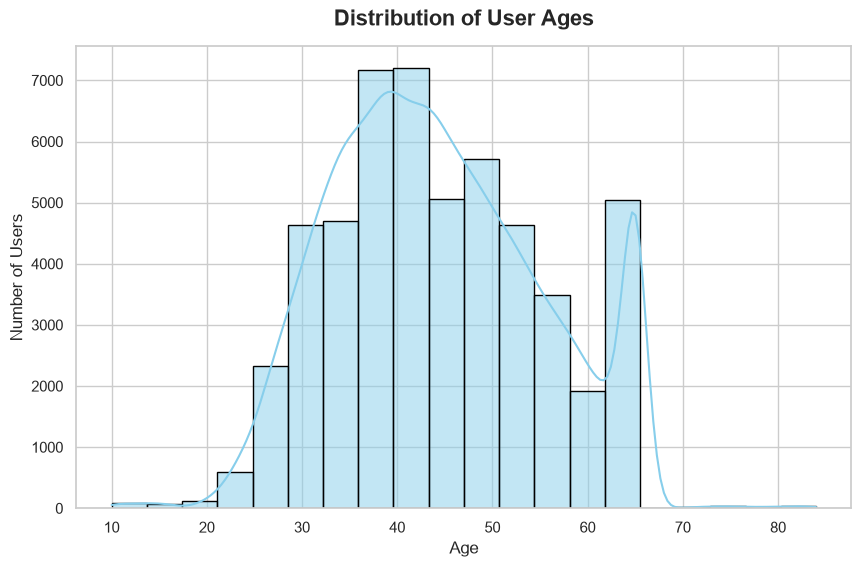

In [39]:
# Set style for the visualization
sns.set_theme(style="whitegrid")
plt.figure(figsize=(10, 6))

# Plotting the age distribution using a histogram
sns.histplot(data=clean_users, x="age", bins=20, kde=True, color="skyblue", edgecolor="black")

# Adding titles and labels
plt.title("Distribution of User Ages", fontsize=16, fontweight="bold", pad=15)
plt.xlabel("Age", fontsize=12)
plt.ylabel("Number of Users", fontsize=12)

# Show the plot
plt.show()

Tidak terlihat ada nilai yang janggal dari jumlah user per umur. Karena Tokopedia secara eksplisit tidak melarang pengguna dibawah umur 18 tahun, ataupun batasan umur yang lainnya, maka pengguna-pengguna di rentang umur tersebut tidak termasuk nilai janggal.

### 5.2 Mengecek jika ada user yang memiliki join_date lebih lama dibanding umur mereka

In [40]:
ageAnalysis = clean_users[["age", "join_date"]].copy()
ageAnalysis

,age,join_date
0,35,2024-12-07
1,46,2023-11-10
2,41,2023-10-14
3,65,2024-10-05
4,51,2020-12-19
...,...,...
52842,33,2024-11-27
52843,47,2020-09-25
52844,56,2024-10-21
52845,42,2024-01-17


In [41]:
# Ekstrak tahun dari join_date
clean_users['join_date'] = pd.to_datetime(clean_users['join_date'])
clean_users['join_year'] = clean_users['join_date'].dt.year

# Hitung perkiraan tahun lahir (menggunakan acuan batas akhir pengambilan data, yaitu 2024)
clean_users['birth_year'] = 2024 - clean_users['age']

# Mencari anomali (tahun join lebih kecil/sebelum tahun lahir)
anomali = clean_users[clean_users['join_year'] < clean_users['birth_year']]
print(f"Total baris anomali: {len(anomali)}")

Total baris anomali: 0


### 5.3 Mengecek jika ada user dengan last_active_date lebih lama dibanding join_date

In [42]:
# import pandas as pd

# # Memuat dataset ke dalam variabel clean_users
# clean_users = pd.read_csv("users.csv")

# Mengonversi kedua kolom menjadi objek datetime agar komparasi kronologis valid
clean_users['join_date'] = pd.to_datetime(clean_users['join_date'])
clean_users['last_active_date'] = pd.to_datetime(clean_users['last_active_date'])

# Memfilter baris di mana last_active_date terjadi sebelum join_date
anomali_waktu = clean_users[clean_users['last_active_date'] < clean_users['join_date']]

# Menampilkan total baris anomali beserta beberapa sampelnya
print(f"Total anomali: {len(anomali_waktu)}")
print(anomali_waktu[['user_id', 'join_date', 'last_active_date']].head())

Total anomali: 0
Empty DataFrame
Columns: [user_id, join_date, last_active_date]
Index: []


## **6. Missing Relational Values**
Tidak semua pesanan memiliki data pengiriman maupun tiket layanan — cakupan kedua tabel tersebut
bersifat parsial. Disarankan memverifikasi konsistensi relasi antar tabel (mis. kunci pengguna dan pesanan)
sebelum menggabungkan tabel untuk analisis lanjutan.

In [43]:
print("=== Orphan key: foreign key tidak ada di tabel induk ===")
orphan_user = ~clean_transactions['user_id'].isin(clean_users['user_id'])
orphan_seller = ~clean_transactions['seller_id'].isin(clean_sellers['seller_id'])
orphan_delivery = ~clean_deliveries['order_id'].isin(clean_transactions['order_id'])
orphan_ticket = ~clean_customer_service_tickets['order_id'].isin(clean_transactions['order_id'])
print("transactions.user_id   -> users   :", orphan_user.sum())
print("transactions.seller_id -> sellers :", orphan_seller.sum())
print("deliveries.order_id    -> transactions:", orphan_delivery.sum())
print("tickets.order_id       -> transactions:", orphan_ticket.sum())

print("\n=== Induk tanpa anak ===")
print("users tanpa transaksi   :", (~clean_users['user_id'].isin(clean_transactions['user_id'])).sum())
print("sellers tanpa transaksi :", (~clean_sellers['seller_id'].isin(clean_transactions['seller_id'])).sum())
order_unik = clean_transactions.drop_duplicates('order_id')
tanpa_delivery = ~order_unik['order_id'].isin(clean_deliveries['order_id'])
print("order tanpa delivery    :", tanpa_delivery.sum())
print(order_unik[tanpa_delivery]['order_status'].value_counts())

print("\n=== Duplikat kunci relasi ===")
kolom_isi = [c for c in clean_transactions.columns if c != 'transaction_key']
print("transactions: order_id duplikat       :", clean_transactions['order_id'].duplicated().sum())
print("transactions: duplikat identik penuh  :", clean_transactions.duplicated(subset=kolom_isi).sum())
print("deliveries  : order_id duplikat       :", clean_deliveries['order_id'].duplicated().sum())

print("\n=== Sampel orphan user_id ===")
print(clean_transactions[orphan_user][['transaction_key', 'order_id', 'user_id', 'order_status']].head())

=== Orphan key: foreign key tidak ada di tabel induk ===
transactions.user_id   -> users   : 404
transactions.seller_id -> sellers : 0
deliveries.order_id    -> transactions: 0
tickets.order_id       -> transactions: 0

=== Induk tanpa anak ===
users tanpa transaksi   : 267
sellers tanpa transaksi : 0
order tanpa delivery    : 7353
order_status
cancelled    7353
Name: count, dtype: int64

=== Duplikat kunci relasi ===
transactions: order_id duplikat       : 1087
transactions: duplikat identik penuh  : 1071
deliveries  : order_id duplikat       : 12

=== Sampel orphan user_id ===
      transaction_key            order_id     user_id order_status
133               134  INV/230103/5944245  K54SQ6W8UN    completed
1830             1831  INV/230713/5372916  FNX4P2G398    completed
2299             2300  INV/240109/5852085  GVCC3YXMLZ    completed
2805             2806  INV/240114/3689747  68C3K7KQJG    completed
2998             2999  INV/230107/4775695  89E325743R    completed


In [44]:
# ---------- 1. Duplikat identik penuh pada transactions -> hapus (pertahankan transaction_key terkecil) ----------
kolom_isi = [c for c in transactions.columns if c != 'transaction_key']
sebelum = len(clean_transactions)
clean_transactions = clean_transactions.sort_values('transaction_key')
clean_transactions = clean_transactions.drop_duplicates(subset=kolom_isi, keep='first')
print(f"Baris duplikat identik dihapus: {sebelum - len(clean_transactions):,} ({sebelum:,} -> {len(clean_transactions):,})")

# ---------- 2. order_id bentrok (order_id sama, isi beda) -> flag, jangan dihapus ----------
clean_transactions['flag_order_id_bentrok'] = clean_transactions['order_id'].duplicated(keep=False)
clean_deliveries['flag_order_id_bentrok'] = clean_deliveries['order_id'].duplicated(keep=False)

# ---------- 3. Orphan user_id (404 transaksi) -> flag, jangan dihapus ----------
clean_transactions['flag_user_tidak_terdaftar'] = ~clean_transactions['user_id'].isin(clean_users['user_id'])
daftar_user_hilang = (clean_transactions.loc[clean_transactions['flag_user_tidak_terdaftar'], ['user_id']]
                      .drop_duplicates().reset_index(drop=True))   # untuk dikonfirmasi ke pemilik data

# ---------- 4. Cakupan parsial -> beri indikator agar analisis tidak keliru ----------
punya_kirim = clean_transactions['order_id'].isin(clean_deliveries['order_id'])
clean_transactions['punya_pengiriman'] = punya_kirim
clean_transactions['punya_tiket'] = clean_transactions['order_id'].isin(clean_customer_service_tickets['order_id'])
clean_transactions['status_cakupan_pengiriman'] = np.select(
    [punya_kirim, ~punya_kirim & (clean_transactions['order_status'] == 'cancelled')],
    ['Ada Pengiriman', 'Tanpa Pengiriman (Dibatalkan)'],
    default='Tanpa Pengiriman (Anomali)')

clean_users['belum_pernah_transaksi'] = ~clean_users['user_id'].isin(clean_transactions['user_id'])

# ---------- 5. Verifikasi ----------
print("\n=== Verifikasi setelah aksi ===")
print("transactions: duplikat identik penuh      :", clean_transactions.duplicated(subset=kolom_isi).sum())
print("transactions: baris order_id bentrok      :", clean_transactions['flag_order_id_bentrok'].sum(),
      f"({clean_transactions.loc[clean_transactions['flag_order_id_bentrok'], 'order_id'].nunique()} order_id)")
print("deliveries  : baris order_id bentrok      :", clean_deliveries['flag_order_id_bentrok'].sum(),
      f"({clean_deliveries.loc[clean_deliveries['flag_order_id_bentrok'], 'order_id'].nunique()} order_id)")
print("transactions: user_id tidak terdaftar     :", clean_transactions['flag_user_tidak_terdaftar'].sum(),
      f"({len(daftar_user_hilang)} user_id unik)")
print("users       : belum pernah transaksi      :", clean_users['belum_pernah_transaksi'].sum())
print("\nstatus_cakupan_pengiriman:")
print(clean_transactions['status_cakupan_pengiriman'].value_counts().to_string())
print("\npunya_tiket:")
print(clean_transactions['punya_tiket'].value_counts().to_string())

Baris duplikat identik dihapus: 1,071 (269,953 -> 268,882)

=== Verifikasi setelah aksi ===
transactions: duplikat identik penuh      : 0
transactions: baris order_id bentrok      : 32 (16 order_id)
deliveries  : baris order_id bentrok      : 24 (12 order_id)
transactions: user_id tidak terdaftar     : 404 (404 user_id unik)
users       : belum pernah transaksi      : 267

status_cakupan_pengiriman:
status_cakupan_pengiriman
Ada Pengiriman                   261529
Tanpa Pengiriman (Dibatalkan)      7353

punya_tiket:
punya_tiket
False    237327
True      31555


## **Exporting Dataset**

In [45]:
clean_customer_service_tickets.to_csv("clean_customer_service_tickets.csv", index=False)
clean_deliveries.to_csv("clean_deliveries.csv", index=False)
clean_sellers.to_csv("clean_sellers.csv", index=False)
clean_transactions.to_csv("clean_transactions.csv", index=False)
clean_users.to_csv("clean_users.csv", index=False)